**Public archival copy.** Saved cell outputs (including embedded images) and Colab-specific runtime metadata have been removed. Original code and explanatory cell content remain unchanged. Some code refers to Google Drive paths and intermediate research artifacts that are not distributed here. The Fitzpatrick17k image files and the researchers' individual access link are **not included**. See `notebooks/README.md` for access and reproducibility notes.


# Phase 2 — Baseline ResNet-50

## Objective
This phase establishes a standard deep learning baseline for binary skin lesion classification using the Fitzpatrick17k dataset. The objective is to evaluate the performance of a conventional ResNet-50 model under the original demographic and class distribution, without applying any balancing or domain-invariant learning techniques.

### Binary Classification
- Benign
- Malignant

### Skin-Tone Domains
- Light: Fitzpatrick I–III
- Dark: Fitzpatrick IV–VI

### Baseline Constraints
No:
- Oversampling
- Undersampling
- Class weighting
- Class-balanced loss
- WeightedRandomSampler
- MMD
- Domain adaptation
- Fairness-specific training methods

The baseline is intended to establish the natural performance and demographic performance gap that will later be compared against the proposed approaches.

In [ ]:
# ============================================
# Phase 2 — Baseline ResNet-50
# Imports & Configuration
# ============================================

import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import matplotlib.pyplot as plt

# ============================================
# Experiment Configuration
# ============================================

SEED = 42

BATCH_SIZE = 32
IMAGE_SIZE = 224

NUM_CLASSES = 2

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

NUM_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 10

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"Device: {DEVICE}")

# ============================================
# Reproducibility
# ============================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Ensures reproducible CUDA behavior where possible
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

For the baseline experiment, we're locking:

- Seed: 42
- Image size: 224×224
- Batch size: 32
- ResNet-50: later
- Loss: standard CrossEntropyLoss
- Learning rate: 1e-4
- Weight decay: 1e-4
- Maximum epochs: 50
- Early stopping: 10 epochs
- GPU: automatically used if available

Nothing here introduces balancing or domain-invariant methods.

In [ ]:
# ============================================
# Load Fitzpatrick17k Metadata
# ============================================

DATASET_URL = "https://raw.github.com/mattgroh/fitzpatrick17k/main/fitzpatrick17k.csv"

df = pd.read_csv(DATASET_URL)

print(f"Original dataset size: {len(df):,}")
print(f"Columns: {list(df.columns)}")


# ============================================
# Phase 2 Dataset Filtering
# ============================================

# Keep only samples with a valid Fitzpatrick skin-tone label
# and binary benign/malignant classification.

model_df = df[
    (df["fitzpatrick_scale"] != -1) &
    (df["three_partition_label"].isin(["benign", "malignant"]))
].copy()

print(f"Modeling dataset size: {len(model_df):,}")


# ============================================
# Construct Skin-Tone Domains
# ============================================

model_df["skin_tone"] = np.where(
    model_df["fitzpatrick_scale"].between(1, 3),
    "Light",
    "Dark"
)

# Binary target
model_df["target"] = model_df["three_partition_label"].map({
    "benign": 0,
    "malignant": 1
})

print("\nSkin-tone distribution:")
print(model_df["skin_tone"].value_counts())

print("\nClass distribution:")
print(model_df["three_partition_label"].value_counts())


# ============================================
# Combined Stratification Group
# ============================================

model_df["stratify_group"] = (
    model_df["skin_tone"] + "_" +
    model_df["three_partition_label"]
)

print("\nCombined distribution:")
print(model_df["stratify_group"].value_counts())

Light = 3,241 vs Dark = 1,079 → substantial skin-tone imbalance.
Benign = 2,160 and Malignant = 2,160 → the overall disease classes are perfectly balanced.
However, the four subgroup combinations are not balanced, which is exactly why our stratification needs to preserve all four groups.
We have not applied any balancing technique. Good.
target = 0 for benign and 1 for malignant is appropriate for the binary classifier.

In [ ]:
# ============================================
# Train / Validation / Test Split
# ============================================

# First split:
# 70% Training
# 30% Temporary (Validation + Test)

train_df, temp_df = train_test_split(
    model_df,
    test_size=0.30,
    random_state=SEED,
    stratify=model_df["stratify_group"]
)

# Second split:
# 15% Validation
# 15% Test
#
# Since temp_df is 30% of the original dataset,
# splitting it 50/50 gives 15% validation and 15% test.

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["stratify_group"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Dataset split:")
print(f"Train:      {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Test:       {len(test_df):,}")

print("\nPercentages:")
print(f"Train:      {len(train_df) / len(model_df) * 100:.2f}%")
print(f"Validation: {len(val_df) / len(model_df) * 100:.2f}%")
print(f"Test:       {len(test_df) / len(model_df) * 100:.2f}%")

Verify Stratified Distribution

In [ ]:
# ============================================
# Verify Stratified Distribution
# ============================================

def show_split_distribution(data, name):
    distribution = (
        data["stratify_group"]
        .value_counts()
        .sort_index()
    )

    percentages = (
        data["stratify_group"]
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    result = pd.DataFrame({
        "Count": distribution,
        "Percentage": percentages.round(2)
    })

    print(f"\n{name} Set")
    print("-" * 40)
    print(result)


show_split_distribution(train_df, "Training")
show_split_distribution(val_df, "Validation")
show_split_distribution(test_df, "Test")

# ============================================
# Verify Skin-Tone and Class Distributions
# ============================================

for data, name in [
    (train_df, "Training"),
    (val_df, "Validation"),
    (test_df, "Test")
]:
    print(f"\n{name} Set")
    print("-" * 40)

    print("Skin tone:")
    print(
        data["skin_tone"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print("\nClass:")
    print(
        data["three_partition_label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

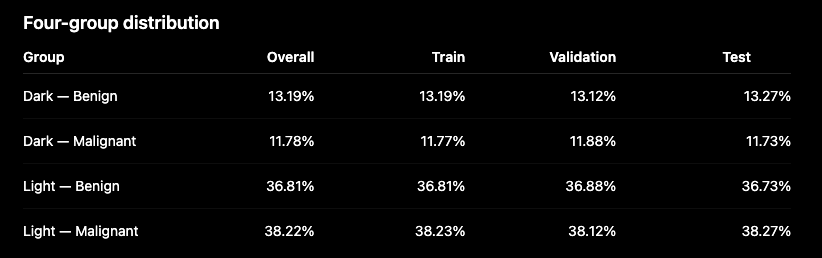

Light/Dark = 75/25 in every split.
Benign/Malignant = 50/50 in every split.
No oversampling.
No undersampling.
No weighting.
No balancing.

So the split itself isn't introducing a demographic or class-distribution difference.

Although the overall benign/malignant classes are balanced, the skin-tone domains remain substantially imbalanced.

In [ ]:
# ============================================
# Check for Duplicate Images Across Splits
# ============================================

train_hashes = set(train_df["md5hash"])
val_hashes = set(val_df["md5hash"])
test_hashes = set(test_df["md5hash"])

train_val_overlap = train_hashes.intersection(val_hashes)
train_test_overlap = train_hashes.intersection(test_hashes)
val_test_overlap = val_hashes.intersection(test_hashes)

print("Duplicate / overlap check:")
print("-" * 40)

print(f"Train ∩ Validation: {len(train_val_overlap)}")
print(f"Train ∩ Test:       {len(train_test_overlap)}")
print(f"Validation ∩ Test:  {len(val_test_overlap)}")

we'll create a PyTorch Dataset that:

- Takes a dataframe.
- Reads an image from its URL.
- Converts it to RGB.
- Applies the appropriate transform.
- Returns:
  - image tensor
  - binary label
  - skin-tone domain

We'll keep the domain information because we need it during evaluation, even though the model itself will not receive skin tone as an input.

One important distinction:

> Skin tone is metadata for evaluation, not a model feature.

The ResNet will only see the image.

In [ ]:
# ============================================
# PyTorch Dataset
# ============================================

from PIL import Image
from io import BytesIO
import requests


class SkinLesionDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        # Load image from URL
        response = requests.get(row["url"], timeout=15)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content)).convert("RGB")

        # Apply image transformations
        if self.transform:
            image = self.transform(image)

        # Binary classification target
        label = torch.tensor(
            row["target"],
            dtype=torch.long
        )

        # Skin-tone domain retained only for evaluation
        skin_tone = row["skin_tone"]

        return image, label, skin_tone

In [ ]:
# ============================================
# Fitzpatrick17k Local Image Directory
# ============================================

from google.colab import drive
import os

drive.mount("/content/drive")

In [ ]:


IMAGE_DIR = "/content/drive/MyDrive/finalfitz17k"

print("Image directory exists:", os.path.exists(IMAGE_DIR))

image_files = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print(f"Number of image files found: {len(image_files):,}")
print("\nFirst 5 files:")
print(image_files[:5])

In [ ]:
# ============================================
# Verify Metadata-to-Image Mapping
# ============================================

available_image_hashes = {
    os.path.splitext(filename)[0]
    for filename in image_files
}

model_df["image_exists"] = model_df["md5hash"].isin(
    available_image_hashes
)

print("Image mapping verification:")
print("-" * 40)

print(f"Total modeling samples: {len(model_df):,}")
print(f"Images found:           {model_df['image_exists'].sum():,}")
print(f"Images missing:         {(~model_df['image_exists']).sum():,}")

In [ ]:
# ============================================
# Create Local Image Paths
# ============================================

model_df["image_path"] = (
    IMAGE_DIR + "/" + model_df["md5hash"] + ".jpg"
)

train_df["image_path"] = (
    IMAGE_DIR + "/" + train_df["md5hash"] + ".jpg"
)

val_df["image_path"] = (
    IMAGE_DIR + "/" + val_df["md5hash"] + ".jpg"
)

test_df["image_path"] = (
    IMAGE_DIR + "/" + test_df["md5hash"] + ".jpg"
)

print("Example image path:")
print(train_df["image_path"].iloc[0])

In [ ]:
# ============================================
# Verify Local Image
# ============================================

sample_row = train_df.iloc[0]

sample_image = Image.open(
    sample_row["image_path"]
).convert("RGB")

print("Image loaded successfully.")
print(f"Path: {sample_row['image_path']}")
print(f"Size: {sample_image.size}")
print(f"Mode: {sample_image.mode}")
print(f"Label: {sample_row['three_partition_label']}")
print(f"Skin tone: {sample_row['skin_tone']}")

plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.axis("off")
plt.title(
    f"{sample_row['three_partition_label']} | "
    f"{sample_row['skin_tone']} | "
    f"Fitzpatrick {sample_row['fitzpatrick_scale']}"
)
plt.show()

In [ ]:
# ============================================
# Local Image PyTorch Dataset
# ============================================

class SkinLesionDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Load local image
        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        # Apply transformations
        if self.transform is not None:
            image = self.transform(image)

        # Binary classification target
        label = torch.tensor(
            row["target"],
            dtype=torch.long
        )

        # Retain skin tone for subgroup evaluation
        skin_tone = row["skin_tone"]

        return image, label, skin_tone

In [ ]:
# ============================================
# Image Transformations
# ============================================

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
# ============================================
# Create Dataset Objects
# ============================================

train_dataset = SkinLesionDataset(
    train_df,
    transform=train_transform
)

val_dataset = SkinLesionDataset(
    val_df,
    transform=eval_transform
)

test_dataset = SkinLesionDataset(
    test_df,
    transform=eval_transform
)

print("Dataset sizes:")
print(f"Train:      {len(train_dataset):,}")
print(f"Validation: {len(val_dataset):,}")
print(f"Test:       {len(test_dataset):,}")

In [ ]:
# ============================================
# DataLoaders
# ============================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders created successfully.")
print(f"Training batches:   {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches:       {len(test_loader)}")

The training loader has 95 batches because:

> 3024 / 32 = 94.5

so the final batch contains the remaining samples.

In [ ]:
# ============================================
# Batch Sanity Check
# ============================================

images, labels, skin_tones = next(iter(train_loader))

print("Batch loaded successfully.")
print("-" * 40)
print(f"Image tensor shape: {images.shape}")
print(f"Label tensor shape: {labels.shape}")
print(f"Labels: {labels[:10].tolist()}")
print(f"Skin tones: {skin_tones[:10]}")
print(f"Image dtype: {images.dtype}")
print(f"Label dtype: {labels.dtype}")

We're going to use ImageNet-pretrained ResNet-50, with only the final classification layer changed from 1000 classes to our 2 classes.

This is still a completely standard baseline. We're not giving the model skin-tone information, and we're not using any balancing.

In [ ]:
# ============================================
# ResNet-50 Baseline Model
# ============================================

weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(weights=weights)

# Replace the final classification layer
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    NUM_CLASSES
)

model = model.to(DEVICE)

print(model.fc)
print(f"\nModel device: {DEVICE}")

In [ ]:
# ============================================
# GPU Check
# ============================================

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        f"GPU memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )
else:
    print("WARNING: GPU is not available.")

Before setting up training, let's verify that the model actually accepts our batch and produces exactly two outputs per image.

In [ ]:
# ============================================
# ResNet-50 Forward Pass Sanity Check
# ============================================

model.eval()

with torch.no_grad():
    images, labels, skin_tones = next(iter(train_loader))

    images = images.to(DEVICE)
    labels = labels.to(DEVICE)

    outputs = model(images)

print("Forward pass successful.")
print("-" * 40)
print(f"Input shape:  {images.shape}")
print(f"Output shape: {outputs.shape}")
print(f"Label shape:  {labels.shape}")

In [ ]:
# ============================================
# Loss Function, Optimizer & Scheduler
# ============================================

# Standard unweighted cross-entropy loss
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Reduce learning rate when validation loss stops improving
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.1,
    patience=3
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Initial learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

We're deliberately using:

CrossEntropyLoss

with no weighting whatsoever.

So we are not doing:

❌ class weights
❌ weighted sampler
❌ class-balanced loss
❌ oversampling
❌ undersampling

The optimizer is simply:

Adam
LR = 1e-4
Weight decay = 1e-4

And the scheduler only changes the learning rate based on validation loss. It doesn't balance the dataset.

In [ ]:
# ============================================
# Training Function
# ============================================

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels, _ in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
# ============================================
# Validation Function
# ============================================

def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels, _ in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

Now let's build the actual training loop with:

Early stopping
Best model checkpointing
Training/validation history tracking
Learning rate scheduling

In [ ]:
# ============================================
# Full Training Loop
# ============================================

best_val_loss = float("inf")

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

epochs_without_improvement = 0

for epoch in range(NUM_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_resnet50_baseline.pth"
        )

        epochs_without_improvement = 0

        print("✓ Best model saved")

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\nEarly stopping triggered.")
        break

In [ ]:
# ============================================
# Load Best Validation Model
# ============================================

model.load_state_dict(
    torch.load(
        "best_resnet50_baseline.pth",
        map_location=DEVICE
    )
)

model.eval()

print("Best model loaded successfully.")
print(f"Best validation loss: {best_val_loss:.4f}")

In [ ]:
# ============================================
# Training Curves
# ============================================

plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.show()

In [ ]:
# ============================================
# Generate Test-Set Predictions
# ============================================

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []
all_skin_tones = []

with torch.no_grad():

    for images, labels, skin_tones in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)

        # Convert logits to probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Malignant probability
        malignant_probabilities = probabilities[:, 1]

        # Predicted class
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            malignant_probabilities.cpu().numpy()
        )
        all_skin_tones.extend(skin_tones)

print("Test predictions generated successfully.")
print(f"Number of test samples: {len(all_labels)}")

In [ ]:
# ============================================
# Overall Test-Set Metrics
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# Convert to NumPy arrays
y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

# Calculate metrics
overall_accuracy = accuracy_score(y_true, y_pred)
overall_precision = precision_score(y_true, y_pred, zero_division=0)
overall_recall = recall_score(y_true, y_pred, zero_division=0)
overall_f1 = f1_score(y_true, y_pred, zero_division=0)
overall_roc_auc = roc_auc_score(y_true, y_prob)
overall_balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

print("Overall Test-Set Performance")
print("=" * 45)
print(f"Accuracy:          {overall_accuracy:.4f}")
print(f"Precision:         {overall_precision:.4f}")
print(f"Recall:            {overall_recall:.4f}")
print(f"F1-score:          {overall_f1:.4f}")
print(f"ROC-AUC:           {overall_roc_auc:.4f}")
print(f"Balanced Accuracy: {overall_balanced_accuracy:.4f}")

print("\nClassification Report")
print("=" * 45)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Benign", "Malignant"],
        digits=4,
        zero_division=0
    )
)

In [ ]:
# ============================================
# Overall Confusion Matrix
# ============================================

cm = confusion_matrix(y_true, y_pred)

print("Overall Confusion Matrix")
print("=" * 35)
print(cm)

In [ ]:
# ============================================
# Performance by Skin Tone
# ============================================

skin_tones_array = np.array(all_skin_tones)

def calculate_metrics(y_true, y_pred, y_prob):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, y_prob
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        )
    }


results = {}

for tone in ["Light", "Dark"]:

    mask = skin_tones_array == tone

    tone_true = y_true[mask]
    tone_pred = y_pred[mask]
    tone_prob = y_prob[mask]

    results[tone] = calculate_metrics(
        tone_true,
        tone_pred,
        tone_prob
    )

    print(f"\n{tone} Skin")
    print("=" * 45)
    print(f"Samples:           {len(tone_true)}")

    for metric, value in results[tone].items():
        print(f"{metric + ':':<20} {value:.4f}")

![image.png](
  
)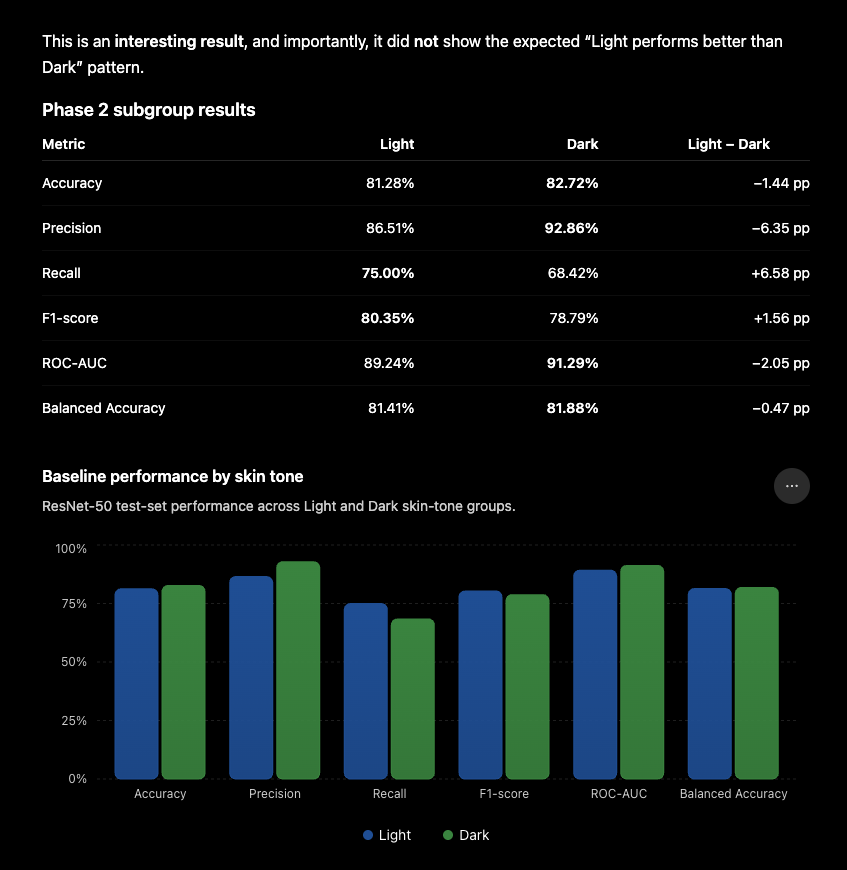

We cannot claim that the baseline demonstrates lower overall performance on Dark skin.

In fact:

Dark accuracy is 1.44 percentage points higher.
Dark ROC-AUC is 2.05 points higher.
Dark balanced accuracy is almost identical, only 0.47 points higher.
Dark precision is substantially higher.
But Dark recall is 6.58 points lower, meaning the model is worse at detecting malignant cases among Dark-skin samples.

That last point is particularly important for your research.

The baseline therefore appears to show a difference in error behavior rather than a simple overall performance disadvantage.

But don't call this "bias" yet

This is where we need to be scientifically careful.

Your Dark test group has only:

162 images

versus:

486 Light images.

So the Dark subgroup estimate is considerably less stable. Also, we haven't yet broken the results down into benign vs malignant within each skin-tone group.

That analysis is crucial.

For example, Dark recall of 68.42% could mean the model is particularly poor at recognizing malignant Dark-skin lesions. We need to see that directly.

In [ ]:
# ============================================
# Confusion Matrices by Skin Tone
# ============================================

for tone in ["Light", "Dark"]:

    mask = skin_tones_array == tone

    tone_true = y_true[mask]
    tone_pred = y_pred[mask]

    cm = confusion_matrix(
        tone_true,
        tone_pred
    )

    print(f"\n{tone} Skin")
    print("=" * 40)
    print("              Predicted")
    print("              Benign  Malignant")
    print(f"Actual Benign     {cm[0,0]:3d}      {cm[0,1]:3d}")
    print(f"Actual Malignant  {cm[1,0]:3d}      {cm[1,1]:3d}")

What the confusion matrices show

Light skin:

                  Predicted
                Benign  Malignant
Actual Benign     209       29
Actual Malignant   62      186

So malignant recall is:

186 / (186 + 62) = 75.00%

Dark skin:

                  Predicted
                Benign  Malignant
Actual Benign      82        4
Actual Malignant   24       52

So malignant recall is:

52 / (52 + 24) = 68.42%
The important finding

The baseline makes fewer false-positive errors on Dark skin, but it misses a larger proportion of malignant Dark-skin lesions.

Error type	Light	Dark
False positives	29 / 238	4 / 86
False negatives	62 / 248	24 / 76
Malignant recall	75.00%	68.42%
Benign recall	87.82%	95.35%

So the model's overall Dark-skin accuracy being slightly higher is somewhat misleading. The more clinically relevant malignant-class sensitivity is lower for Dark skin by 6.58 percentage points.

However, 24 missed malignant Dark-skin cases out of 76 is a small subgroup, so we should not make a strong causal/bias claim from this alone.

One correction to our interpretation

Earlier we said:

"We expect higher performance on light skin, lower performance on dark skin."

That's a hypothesis, not something we are required to observe.

Your actual baseline result is more nuanced:

Overall performance is broadly comparable between Light and Dark skin, but the model exhibits lower malignant recall for Dark skin.

That's actually a more interesting research finding than simply getting the expected result.

In [ ]:
# ============================================
# Classification Reports by Skin Tone
# ============================================

for tone in ["Light", "Dark"]:

    mask = skin_tones_array == tone

    tone_true = y_true[mask]
    tone_pred = y_pred[mask]

    print(f"\n{tone} Skin")
    print("=" * 50)

    print(
        classification_report(
            tone_true,
            tone_pred,
            target_names=["Benign", "Malignant"],
            digits=4,
            zero_division=0
        )
    )

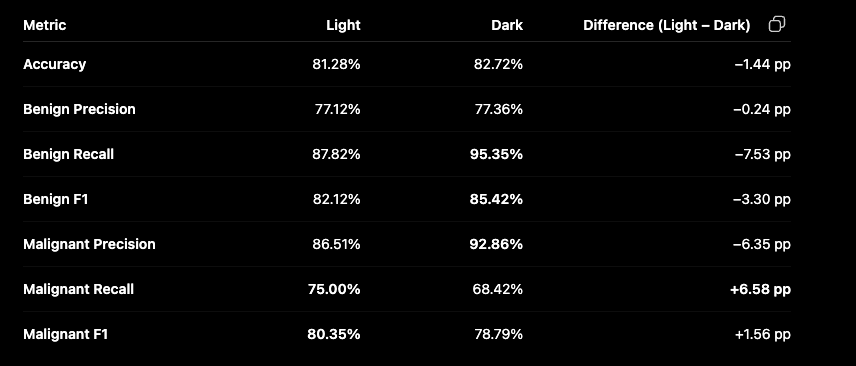

The baseline is not simply worse on Dark skin.

Instead, there is a very specific pattern:

Dark skin

Excellent benign recall: 95.35%
Higher malignant precision: 92.86%
Lower malignant recall: 68.42%

Light skin

Lower benign recall: 87.82%
Lower malignant precision: 86.51%
Higher malignant recall: 75.00%

So the model appears to have a different error profile across skin tones.

The clinically important difference is:

Malignant recall is 6.58 percentage points lower for Dark skin.

That means the baseline missed a greater proportion of malignant lesions in the Dark subgroup.

But we should phrase the thesis result carefully:

> The baseline model did not exhibit a uniform performance disadvantage on Dark skin. Instead, subgroup analysis revealed a disparity in malignant sensitivity, with malignant recall decreasing from 75.00% for Light skin to 68.42% for Dark skin, despite comparable overall accuracy and balanced accuracy.

In [ ]:
# ============================================
# 95% Bootstrap Confidence Intervals
# ============================================

from sklearn.utils import resample

def bootstrap_metric_ci(
    y_true,
    y_pred,
    y_prob,
    metric_function,
    n_bootstrap=2000,
    random_state=42
):

    rng = np.random.RandomState(random_state)
    scores = []

    n = len(y_true)

    for _ in range(n_bootstrap):

        indices = rng.randint(0, n, n)

        sample_true = y_true[indices]
        sample_pred = y_pred[indices]
        sample_prob = y_prob[indices]

        # ROC-AUC requires both classes
        if metric_function == "roc_auc":
            if len(np.unique(sample_true)) < 2:
                continue

            score = roc_auc_score(
                sample_true,
                sample_prob
            )

        elif metric_function == "accuracy":
            score = accuracy_score(
                sample_true,
                sample_pred
            )

        elif metric_function == "malignant_recall":
            score = recall_score(
                sample_true,
                sample_pred,
                zero_division=0
            )

        scores.append(score)

    lower = np.percentile(scores, 2.5)
    upper = np.percentile(scores, 97.5)

    return lower, upper


for tone in ["Light", "Dark"]:

    mask = skin_tones_array == tone

    tone_true = y_true[mask]
    tone_pred = y_pred[mask]
    tone_prob = y_prob[mask]

    print(f"\n{tone} Skin")
    print("=" * 50)

    for metric_name in [
        "accuracy",
        "malignant_recall",
        "roc_auc"
    ]:

        lower, upper = bootstrap_metric_ci(
            tone_true,
            tone_pred,
            tone_prob,
            metric_name
        )

        if metric_name == "accuracy":
            point = accuracy_score(
                tone_true,
                tone_pred
            )
            label = "Accuracy"

        elif metric_name == "malignant_recall":
            point = recall_score(
                tone_true,
                tone_pred,
                zero_division=0
            )
            label = "Malignant Recall"

        else:
            point = roc_auc_score(
                tone_true,
                tone_prob
            )
            label = "ROC-AUC"

        print(
            f"{label}: {point:.4f} "
            f"(95% CI: {lower:.4f}–{upper:.4f})"
        )

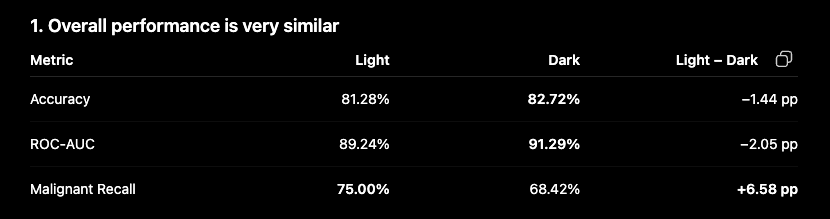

The confidence intervals overlap substantially for all three metrics:

Accuracy

Light: 77.78–84.57%
Dark: 77.16–88.27%

Malignant recall

Light: 69.49–80.17%
Dark: 58.33–78.57%

ROC-AUC

Light: 86.27–92.02%
Dark: 86.11–95.54%

So we should not claim that the observed differences are statistically significant based on these CIs alone.

2. But the malignant-recall pattern is worth investigating

The point estimate is:

75.00% Light vs 68.42% Dark

That's a 6.58-percentage-point gap.

And because malignant detection is the clinically important direction, this is worth carrying forward into Phase 3.

But our wording should remain:

"The baseline exhibited lower malignant recall for Dark-skin lesions."

Not:

"The baseline was proven to be biased against Dark skin."

The latter would be too strong given the current sample size and uncertainty.

In [ ]:
# ============================================
# ROC Curves: Overall vs Skin Tone
# ============================================

from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

# Overall
fpr_overall, tpr_overall, _ = roc_curve(
    y_true,
    y_prob
)

plt.plot(
    fpr_overall,
    tpr_overall,
    label=f"Overall (AUC = {overall_roc_auc:.4f})"
)

# Light
light_mask = skin_tones_array == "Light"

fpr_light, tpr_light, _ = roc_curve(
    y_true[light_mask],
    y_prob[light_mask]
)

plt.plot(
    fpr_light,
    tpr_light,
    label=f"Light (AUC = {roc_auc_score(y_true[light_mask], y_prob[light_mask]):.4f})"
)

# Dark
dark_mask = skin_tones_array == "Dark"

fpr_dark, tpr_dark, _ = roc_curve(
    y_true[dark_mask],
    y_prob[dark_mask]
)

plt.plot(
    fpr_dark,
    tpr_dark,
    label=f"Dark (AUC = {roc_auc_score(y_true[dark_mask], y_prob[dark_mask]):.4f})"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves by Skin Tone")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ============================================
# Final Phase 2 Results Table
# ============================================

phase2_results = pd.DataFrame({
    "Group": [
        "Overall",
        "Light",
        "Dark"
    ],
    "N": [
        len(y_true),
        np.sum(skin_tones_array == "Light"),
        np.sum(skin_tones_array == "Dark")
    ],
    "Accuracy": [
        overall_accuracy,
        results["Light"]["Accuracy"],
        results["Dark"]["Accuracy"]
    ],
    "Precision": [
        overall_precision,
        results["Light"]["Precision"],
        results["Dark"]["Precision"]
    ],
    "Recall": [
        overall_recall,
        results["Light"]["Recall"],
        results["Dark"]["Recall"]
    ],
    "F1-score": [
        overall_f1,
        results["Light"]["F1-score"],
        results["Dark"]["F1-score"]
    ],
    "ROC-AUC": [
        overall_roc_auc,
        results["Light"]["ROC-AUC"],
        results["Dark"]["ROC-AUC"]
    ],
    "Balanced Accuracy": [
        overall_balanced_accuracy,
        results["Light"]["Balanced Accuracy"],
        results["Dark"]["Balanced Accuracy"]
    ]
})

# Display as percentages
phase2_display = phase2_results.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Balanced Accuracy"
]

for column in metric_columns:
    phase2_display[column] = (
        phase2_display[column] * 100
    ).round(2)

phase2_display

In [ ]:
# ============================================
# Light vs Dark Performance Gap
# ============================================

gap_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Balanced Accuracy"
]

gap_results = []

for metric in gap_metrics:

    light_value = results["Light"][metric]
    dark_value = results["Dark"][metric]

    gap_results.append({
        "Metric": metric,
        "Light": light_value * 100,
        "Dark": dark_value * 100,
        "Light - Dark (pp)": (
            light_value - dark_value
        ) * 100
    })

gap_df = pd.DataFrame(gap_results)

gap_df.round(2)

The unbalanced ResNet-50 baseline achieved 81.64% accuracy and 0.8972 ROC-AUC on the overall test set. Overall performance was comparable between Light and Dark skin-tone groups; however, malignant recall was lower for Dark skin (68.42%) than Light skin (75.00%), representing a 6.58-percentage-point disparity. The baseline therefore did not demonstrate a uniform performance disadvantage for Dark skin, but it revealed a potentially important subgroup difference in malignant lesion sensitivity.

In [ ]:
import shutil
import os

SOURCE = "/content/best_resnet50_baseline.pth"
DEST = "/content/drive/MyDrive/best_resnet50_baseline.pth"

shutil.copy2(SOURCE, DEST)

print("Saved to Google Drive:")
print(DEST)
print("Exists:", os.path.exists(DEST))

In [ ]:
phase2_display
gap_df.round(2)

Phase 2 conclusion

The standard ResNet-50 baseline achieved 81.64% accuracy, 80.00% F1-score, and 0.8972 ROC-AUC on the overall test set.

The subgroup analysis did not show a simple overall performance disadvantage for Dark skin. Dark-skin samples actually had slightly higher accuracy (82.72% vs. 81.28%) and ROC-AUC (91.29% vs. 89.24%).

However, the clinically important difference was malignant recall:

Light: 75.00%
Dark: 68.42%
Gap: 6.58 percentage points

The confusion matrices showed that the model correctly identified 186/248 malignant Light-skin cases, compared with 52/76 malignant Dark-skin cases.

Therefore, our Phase 2 finding is not:

"ResNet-50 performs worse on Dark skin."

It is more precise:

The unbalanced baseline demonstrated comparable overall performance across skin-tone groups but showed lower malignant sensitivity for Dark-skin lesions.

That's exactly the kind of baseline finding that gives Phase 3 something meaningful to improve.

What we have locked down

Dataset

4,320 samples
2,160 benign / 2,160 malignant
3,241 Light / 1,079 Dark

Split

Train: 3,024
Validation: 648
Test: 648
Stratified by skin_tone × disease
Zero train/validation/test overlap

Model

ImageNet-pretrained ResNet-50
Standard 2-class output

Training

Standard CrossEntropyLoss
No class weights
No oversampling
No undersampling
No weighted sampler
No domain adaptation
No MMD
No XAI
Standard augmentation only

Checkpoint

best_resnet50_baseline.pth
Saved to Google Drive

Evaluation

Overall metrics
Light/Dark metrics
Confusion matrices
ROC curves
95% bootstrap CIs

So Phase 2 is complete.